In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G_delta"):
    os.makedirs("data/temp_G_delta")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
# Profundidad del NV (nm)
d = 15  
# Coeficientes de difusión
D0 = 2e3        # nm²/s (equiv. a 2e-9 m²/µs)
D_s = 2e1       # nm²/s
# Geometría
R = L = 5 * d 
z_c=0.75*L/d
lambda_param=0.75/d  
# Parámetro κ fijo (nm/s)
varkappa = 0.0  
# Modos y nodos
n_modes_radial = 100
m_max = 100
N_quad = 1000   # para integración numérica
# Parámetros de malla en z
N_z = 45000
alpha_grid = 5.0

In [4]:
# -----------------------------------------------------------------------------
# 2. Malla adaptativa en z y perfil D(z) (NO depende de varkappa)
# -----------------------------------------------------------------------------
# 2.1 Construcción de la malla en z
j_vals = np.arange(N_z)
z = d + L * np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)
h = np.diff(z)  # h_j = z[j] - z[j-1]

# 2.2 Definición de D(z) (función)
def D(z_val,delta):
    """
    Perfil de difusión completo con z en nm:
    D(z) = D_s + (D0 - D_s) * [ (1 - exp(-lambda_param*(z - d))) * (1 - S(z)) + S(z) ],
    con S(z) = 0.5 * [1 + tanh( (z - (z_c + d)) / delta ) ].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c + d)) / delta))
    return D_s + (D0 - D_s) * ((1 - np.exp(-lambda_param * (z_val - d))) * (1 - S) + S)

In [5]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def build_system(n, alpha_n, D_values, z, h):
    """
    Ensambla la matriz tridiagonal A para el modo radial n y la diagonaliza
    para obtener m_max autovalores y autovectores.
    - n: índice del modo radial (0 .. n_modes_radial-1)
    - alpha_n: array con todas las raíces alpha (tamaño n_modes_radial)
    - D_values: perfil D(z) evaluado en todos los nodos z (longitud N_z)
    - z: malla en z (longitud N_z)
    - h: diferencias entre nodos de z (longitud N_z-1)
    - varkappa: valor actual de kappa en nm/s
    Retorna: (n, (evals, evecs)), donde
      - evals: vector de longitud m_max con los m_max autovalores más bajos
      - evecs: matriz (N_z, m_max) con los vectores propios normalizados
    """
    try:
        alpha = alpha_n[n]
        N = len(z)
        main_diag = np.zeros(N)
        upper_diag = np.zeros(N-1)
        lower_diag = np.zeros(N-1)

        # ---------------------------------------------------------------
        # 1. Índices internos (j=1 a N-2)
        # ---------------------------------------------------------------
        j_int = np.arange(1, N-1)  # j=1, 2, ..., N-2
        j_prev = j_int - 1         # j-1 = 0, 1, ..., N-3
        j_next = j_int + 1         # j+1 = 2, 3, ..., N-1
    
        # ---------------------------------------------------------------
        # 2. Cálculo de coeficientes (vectorizado)
        # ---------------------------------------------------------------
        # Promedios armónicos de D en interfases
        D_prev = 2*D_values[j_int]*D_values[j_prev]/(D_values[j_int] + D_values[j_prev])  # D_{j-1/2}
        D_next = 2*D_values[j_int]*D_values[j_next]/(D_values[j_int] + D_values[j_next])  # D_{j+1/2}
        
        # Espaciados promedio
        h_m  = h[j_prev]                 # h_{j-1/2}
        h_p  = h[j_int]                  # h_{j+1/2}
        h_j  = 0.5 * (h_m + h_p)         # h_j
    
        # Términos de la matriz (simétricos)
        main_diag[j_int] = (
              D_prev / (h_m * h_j)    # coeficiente de Z_{j-1}
            + D_next / (h_p * h_j)    # coeficiente de Z_{j+1}
            + alpha**2 * D_values[j_int]
        )
        lower_diag[j_prev] = - D_prev / (h_m * h_j)      # A[j, j-1]
        upper_diag[j_int]  = - D_next / (h_p * h_j)      # A[j, j+1]
    
        # ---------------------------------------------------------------
        # 3. Condiciones de contorno - Simétricas
        # ---------------------------------------------------------------
        # Superficie (z = d)
        h0 = h[0]
        h_1_2=z[1]-z[0]
        D0 = D_values[0]
        D_1_2 = 2*D0*D_values[1]/(D0 + D_values[1])
        
        main_diag[0] = D_1_2/h0/h_1_2 + varkappa/h0 + alpha ** 2 * D0
        upper_diag[0] = -D_1_2/h0/h_1_2
        lower_diag[0] = upper_diag[0]
        
        # Borde superior (z = L + d)
        hL = h[-1]
        h_3_2=z[-1]-z[-2]
        DL = D_values[-1]
        D_3_2 = 2 * D_values[-1] * D_values[-2] / (D_values[-1] + D_values[-2])
        
        main_diag[-1] = D_3_2 / hL/h_3_2 + varkappa / hL + alpha ** 2 * DL
        lower_diag[-2] = -D_3_2 / hL/h_3_2
        upper_diag[-1] = lower_diag[-2]

        # ---------------------------------------------------------------
        # 4. Ensamblar matriz tridiagonal simétrica
        # ---------------------------------------------------------------
        A = diags(
            diagonals=[main_diag, upper_diag, lower_diag],
            offsets=[0, 1, -1],
            shape=(N, N),
            format='csr'
        ) # + 1e-10 * identity(N)
        evals, evecs = eigsh(A, k=m_max, sigma=0.0, which='LM', tol=1e-6, maxiter=10000)
        if n==0 and varkappa==0:
            evals[0]=0.0
        else:
            pass
        return (n, (evals, evecs))

    except ArpackNoConvergence:
        print(f"Advertencia: El modo axial para n={n} no convergió. Se devuelven ceros.")
        return (n, (np.zeros(m_max), np.zeros((len(z), m_max))))

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [6]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
delta_list = [0.01,0.1,1,10,100]

In [8]:
# -----------------------------------------------------------------------------
# 5. Malla temporal y pre-cálculo de f(ρ,z) y medida ρ dρ dz (independientes de δ)
# -----------------------------------------------------------------------------
# 5.1 Nodos de integración en rho y z para G(t):
N_quad = 1000
rho_nodes = np.linspace(0.0, R, N_quad)   # [0, R]
z_nodes  = np.linspace(d, L + d, N_quad)  # [d, L+d]

dr = rho_nodes[1] - rho_nodes[0]
dz = z_nodes[1]  - z_nodes[0]

# 5.2 Factor dipolar f(ρ,z) en la malla (N_quad, N_quad)
R2 = rho_nodes**2
Z2 = (z_nodes + 1e-30)**2   # pequeño desplazamiento para evitar división por cero
f_mat = (3 * Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # shape (Nr, Nz)

# 5.3 Medida cilíndrica ρ dρ dz
measure = rho_nodes[:, None] * dr * dz    # shape (Nr, 1)

# 5.4 Matriz F(ρ,z) = ρ dρ dz f(ρ,z)
F = measure * f_mat                       # shape (Nr, Nz)

# 5.5 Vector de tiempos t en los que se evaluará G(t)
t_values = np.logspace(-3, 7, N_quad)     # shape (N_quad,)

In [10]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada delta, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
D_eff_vals = []

for delta in delta_list:
    print(rf"--- $\delta$ = {delta:.4f} nm ---")
    
    # 6.1 Recalcular D(z) y D_eff
    D_values = D(z, delta)
    integral_D = np.trapezoid(1.0 / D_values, z)
    D_eff = L / integral_D
    D_eff_vals.append(D_eff)

    # 6.2. Hallar raíces alpha_n (n_modes_radial valores)
    alpha_n = find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.3. Modos radiales normalizados en nodos rho_nodes
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # shape (n_modes_radial, N_quad)

    # 6.4. Resolver la parte axial en paralelo para cada modo radial n
    axial_results = Parallel(n_jobs=6, verbose=1)(
        delayed(build_system)(n, alpha_n, D_values, z, h)
        for n in range(n_modes_radial)
    )

    # 6.5. Recolectar autovalores y autovectores axiales
    eigenvalues_ax = {}
    eigenvectors_ax = {}
    for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
        eigenvalues_ax[n]  = evals
        eigenvectors_ax[n] = evecs
    del axial_results
    
    eigenvalues_ax = np.array([
        [eigenvalues_ax[n][m] for m in range(m_max)]
        for n in range(n_modes_radial)
    ])  # shape (n_modes_radial, m_max)

    eigenvectors_ax = np.array([
        [eigenvectors_ax[n][:, m] for m in range(m_max)]
        for n in range(n_modes_radial)
    ])  # shape (n_modes_radial, m_max, N_z)

    # 6.6. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
    norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax.astype(np.float32)**2, z, axis=2))
    norms_ax[norms_ax == 0] = 1.0
    eigenvectors_ax /= norms_ax[:, :, None]
    del norms_ax

    # 6.7. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
    Z_interps = np.empty((n_modes_radial, m_max), dtype=object)
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_interps[n, m] = CubicSpline(z, eigenvectors_ax[n, m, :], extrapolate=False)

    # 6.8. Construcción de Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
    Z_tens = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z_tens[:, n, m] = Z_interps[n, m](z_nodes)

    # -------------------------------------------------------------------------
    # 6.9. Cálculo de los coeficientes de proyección C_{n,m}(δ)
    #      C_nm = ∫ ρ dρ dz f(ρ,z) R_n(ρ) Z_{n,m}(z)
    # -------------------------------------------------------------------------
    C_nm = np.zeros((n_modes_radial, m_max))

    for n in range(n_modes_radial):
        # g_n(z_k) = ∑_i R_n(ρ_i) F(ρ_i, z_k)
        # R0_mat[n,:] : (N_quad,)
        # F           : (N_quad, N_quad)  -> g_n : (N_quad,)
        g_n = np.dot(R0_mat[n, :], F)   # shape (N_quad,)
        for m in range(m_max):
            # C_nm[n,m] = ∑_k g_n(z_k) Z_{n,m}(z_k)
            C_nm[n, m] = np.dot(g_n, Z_tens[:, n, m])

    # -------------------------------------------------------------------------
    # 6.10. Cálculo de G(t; δ) con la suma espectral
    #       G(t) = (5 / 16π) * ∑_{n,m} C_nm^2 e^{-λ_{nm} t}
    # -------------------------------------------------------------------------
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # (n_modes_radial, m_max)
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((C_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.11. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    temp_filename = os.path.join("data/temp_G_delta", f"G_delta_{delta}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_delta{}".format(delta)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    # Liberamos G_values inmediatamente
    del G_values
    del data_to_save
    del Z_tens
    del Z_interps
    del eigenvalues_ax
    del eigenvectors_ax

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

--- $\delta$ = 0.0100 nm ---


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:  6.3min
[Parallel(n_jobs=6)]: Done 100 out of 100 | elapsed: 16.9min finished


  → Guardado temporal en 'data/temp_G_delta\G_delta_0.01.dat' y liberado G_values.

--- $\delta$ = 0.1000 nm ---


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:  6.0min
[Parallel(n_jobs=6)]: Done 100 out of 100 | elapsed: 16.5min finished


  → Guardado temporal en 'data/temp_G_delta\G_delta_0.1.dat' y liberado G_values.

--- $\delta$ = 1.0000 nm ---


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:  6.0min
[Parallel(n_jobs=6)]: Done 100 out of 100 | elapsed: 16.6min finished


  → Guardado temporal en 'data/temp_G_delta\G_delta_1.dat' y liberado G_values.

--- $\delta$ = 10.0000 nm ---


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:  6.1min
[Parallel(n_jobs=6)]: Done 100 out of 100 | elapsed: 16.4min finished


  → Guardado temporal en 'data/temp_G_delta\G_delta_10.dat' y liberado G_values.

--- $\delta$ = 100.0000 nm ---


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:  5.9min
[Parallel(n_jobs=6)]: Done 100 out of 100 | elapsed: 16.3min finished


  → Guardado temporal en 'data/temp_G_delta\G_delta_100.dat' y liberado G_values.



In [11]:
# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'Variatedelta_G_vs_t.dat' ...")

primero = True
lista_Gcols = []

for delta in delta_list:
    temp_filename = os.path.join("data/temp_G_delta", f"G_delta_{delta}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_del{int(delta*100)}' for delta in delta_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/Variatedelta_G_vs_t.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'Variatedelta_G_vs_t.dat' creado con columnas:")
print("   ", header_cols)

→ Combinando archivos temporales en 'Variatedelta_G_vs_t.dat' ...
→ Archivo final 'Variatedelta_G_vs_t.dat' creado con columnas:
    ['Tiempo(s)', 'G_del1', 'G_del10', 'G_del100', 'G_del1000', 'G_del10000']


In [12]:
df = pd.read_csv("data/Variatedelta_G_vs_t.dat",delim_whitespace=True,comment='#')

C:\Users\allan\AppData\Local\Temp\ipykernel_14112\3534899848.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv("data/Variatedelta_G_vs_t.dat",delim_whitespace=True,comment='#')


In [13]:
tau_values1=t_values*D_eff_vals[0]/d**2
tau_values2=t_values*D_eff_vals[1]/d**2
tau_values3=t_values*D_eff_vals[2]/d**2
tau_values4=t_values*D_eff_vals[3]/d**2
tau_values5=t_values*D_eff_vals[4]/d**2

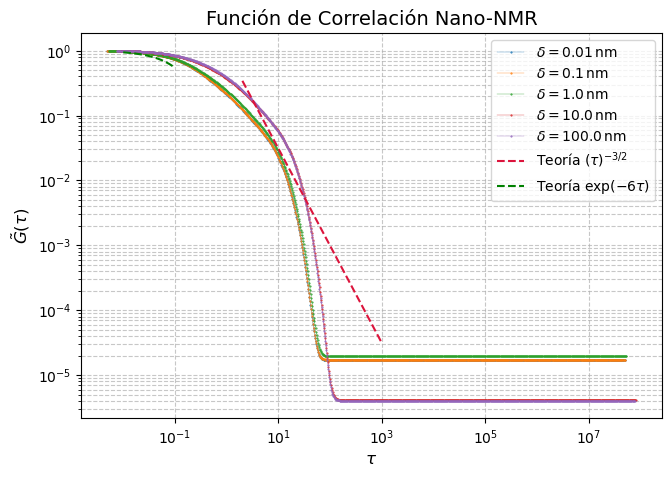

In [14]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values1, df.G_del1/df.G_del1[0], "o-", label=r"$\delta=0.01\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values2, df.G_del10/df.G_del10[0], "o-", label=r"$\delta=0.1\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values3, df.G_del100/df.G_del100[0], "o-", label=r"$\delta=1.0\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values4, df.G_del1000/df.G_del1000[0], "o-", label=r"$\delta=10.0\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values5, df.G_del10000/df.G_del10000[0], "o-", label=r"$\delta=100.0\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values4[(tau_values4>=2)&(tau_values4<=1000)], tau_values4[(tau_values4>=2)&(tau_values4<=1000)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values4[(tau_values4>=1e-2)&(tau_values4<=0.1)], np.exp(-6*tau_values4[(tau_values4>=1e-2)&(tau_values4<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_deltaVariation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

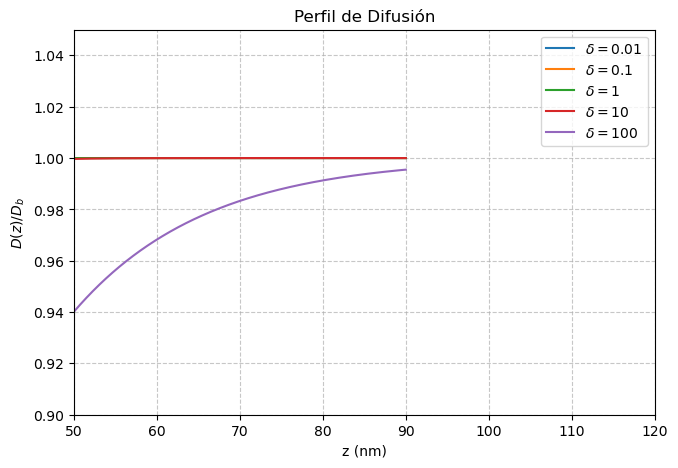

In [15]:
plt.figure(figsize=(7.5,5))
for delta in delta_list:
    D_values=D(z,delta)
    plt.plot(z, D_values/D0,label=rf"$\delta={delta}$", lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel(r'$D(z)/D_b$')
plt.title('Perfil de Difusión')
plt.ylim((0.9,1.05))
plt.xlim((50,120))
plt.grid(ls='--', alpha=0.7)
plt.legend()
plt.savefig('figuras/Dz_profile_deltaVariation.pdf', bbox_inches='tight')
plt.show()
plt.close()